<a href="https://colab.research.google.com/github/prabhnoor14/walmart-hurricane-project/blob/main/notebooks/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

if not os.path.exists('/content/walmart-hurricane-project'):
    !git clone https://github.com/prabhnoor14/walmart-hurricane-project.git

walmart_transactions = pd.read_csv(
    '/content/walmart-hurricane-project/data/walmart_transactions.csv'
)

walmart_transactions_copy = walmart_transactions.drop_duplicates().copy()

walmart_transactions_copy['unit_price'] = (
    walmart_transactions_copy['unit_price']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.strip()
    .astype(float)
)

walmart_transactions_copy['timestamp'] = pd.to_datetime(
    walmart_transactions_copy['timestamp'],
    errors='coerce',
    format='mixed'
)

walmart_transactions_copy['transaction_date'] = (
    walmart_transactions_copy['timestamp'].dt.normalize()
)

walmart_transactions_copy['category'] = (
    walmart_transactions_copy['category'].str.strip().str.title()
)

category_mapping = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Games & Entertainment': 'Entertainment',
    'Groceries': 'Grocery',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household'
}

walmart_transactions_copy['category'] = (
    walmart_transactions_copy['category'].replace(category_mapping)
)

q1_transactions = walmart_transactions_copy.dropna(
    subset=['transaction_date']
).copy()

q1_baseline = q1_transactions[
    q1_transactions['transaction_date'].between(
        '2024-09-01', '2024-09-14'
    )
].copy()

q1_surge = q1_transactions[
    q1_transactions['transaction_date'].between(
        '2024-09-19', '2024-09-25'
    )
].copy()

baseline_avg = q1_baseline.groupby('category')['quantity'].sum() / 14
surge_avg = q1_surge.groupby('category')['quantity'].sum() / 7

q1_comparison = pd.DataFrame({
    'baseline_daily_avg': baseline_avg,
    'surge_daily_avg': surge_avg
})

q1_comparison['surge_multiple'] = (
    q1_comparison['surge_daily_avg']
    / q1_comparison['baseline_daily_avg']
)

q1_comparison['percent_change'] = (
    (q1_comparison['surge_multiple'] - 1) * 100
)

q1_comparison = q1_comparison.sort_values(
    'percent_change', ascending=False
)

print('Baseline window: September 1-14, 2024 (14 days)')
print('Surge window: September 19-25, 2024 (7 days)')
print('Valid transactions:', len(q1_transactions))
print()
print(q1_comparison.round(2))
print()
print('Top category:', q1_comparison.index[0])
print('Baseline daily average:', round(q1_comparison.iloc[0]['baseline_daily_avg'], 2))
print('Surge daily average:', round(q1_comparison.iloc[0]['surge_daily_avg'], 2))
print('Surge multiple:', round(q1_comparison.iloc[0]['surge_multiple'], 2))
print('Percentage increase:', round(q1_comparison.iloc[0]['percent_change'], 2))

Baseline window: September 1-14, 2024 (14 days)
Surge window: September 19-25, 2024 (7 days)
Valid transactions: 24648

               baseline_daily_avg  surge_daily_avg  surge_multiple  \
category                                                             
Breakfast                   73.64           375.71            5.10   
Emergency                  355.36          1002.29            2.82   
Electronics                 69.57           175.29            2.52   
Alcohol                     61.29           138.29            2.26   
Health                      42.00            94.14            2.24   
Entertainment              102.21           227.00            2.22   
Household                   84.86           175.86            2.07   
Grocery                    171.43           305.29            1.78   
Baby                        84.93           132.57            1.56   
Snacks                      58.79            73.71            1.25   

               percent_change  
categor

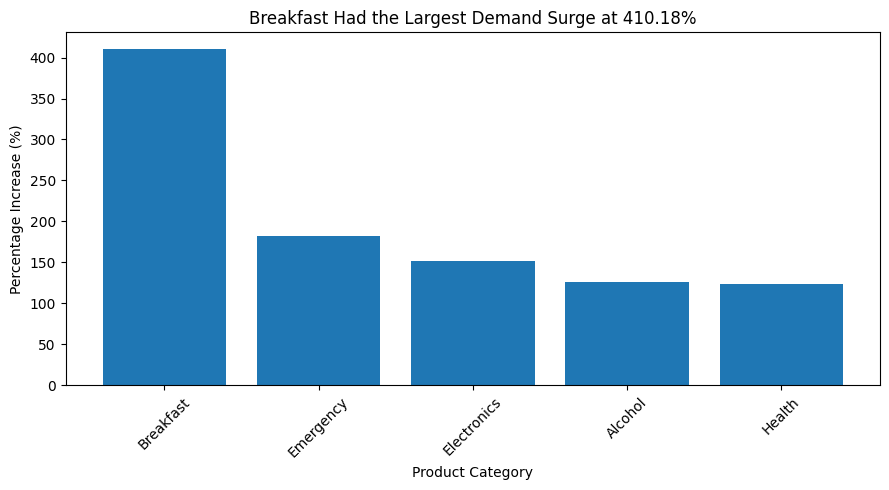

In [2]:
q1_top5 = q1_comparison.head(5)

plt.figure(figsize=(9, 5))

plt.bar(
    q1_top5.index,
    q1_top5['percent_change']
)

top_category = q1_comparison.index[0]
top_increase = q1_comparison.iloc[0]['percent_change']

plt.title(
    f'{top_category} Had the Largest Demand Surge at {top_increase:.2f}%'
)
plt.xlabel('Product Category')
plt.ylabel('Percentage Increase (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** Breakfast had the largest increase in demand before the hurricane, with average daily sales rising from 73.64 units during September 1–14 to 375.71 units during September 19–25, a 5.10 times increase (410.18%).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [3]:
# TODO

**Q2 answer:** _..._

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [4]:
# clean store IDs and load stores
def clean_store_id(col):
    col = col.astype(str).str.strip().str.upper().str.replace('_', '-', regex=False)
    number = col.str.replace('FL', '', regex=False).str.replace('-', '', regex=False)
    return 'FL-' + number

walmart_transactions_copy['store_id'] = clean_store_id(walmart_transactions_copy['store_id'])

stores = pd.read_csv('/content/walmart-hurricane-project/data/store_locations.csv')
stores['store_id'] = clean_store_id(stores['store_id'])
stores = stores.drop_duplicates().reset_index(drop=True)
stores.loc[stores['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]

print(len(stores), 'stores,', stores['latitude'].isna().sum(), 'missing coordinates')

12 stores, 0 missing coordinates


In [5]:
# pull weather from the API
import requests

all_weather = []
for _, store in stores.iterrows():
    params = {
        'latitude': store['latitude'], 'longitude': store['longitude'],
        'start_date': '2024-09-01', 'end_date': '2024-09-30',
        'daily': 'precipitation_sum,wind_speed_10m_max',
        'timezone': 'America/New_York'
    }
    data = requests.get('https://archive-api.open-meteo.com/v1/archive', params=params).json()
    one_store = pd.DataFrame(data['daily'])
    one_store['store_id'] = store['store_id']
    all_weather.append(one_store)

weather = pd.concat(all_weather, ignore_index=True)
weather['date'] = pd.to_datetime(weather['time'])
print(len(weather), 'weather rows (live from the API)')

360 weather rows (live from the API)


In [6]:
# join and check
q3_sales = (walmart_transactions_copy.dropna(subset=['transaction_date'])
            .groupby(['store_id', 'transaction_date'])['quantity'].sum()
            .reset_index()
            .rename(columns={'transaction_date': 'date', 'quantity': 'units'}))

q3_data = q3_sales.merge(weather, on=['store_id', 'date'], how='left')

print('rows before join:', len(q3_sales))
print('rows after join:', len(q3_data))
print('rows missing weather:', q3_data['wind_speed_10m_max'].isna().sum())

rows before join: 360
rows after join: 360
rows missing weather: 0


In [7]:
# correlation and lag
daily = q3_data.groupby('date').agg(
    units=('units', 'sum'),
    wind=('wind_speed_10m_max', 'mean'),
    rain=('precipitation_sum', 'mean'))

print('days in correlation:', len(daily))
print(daily.corr().round(2)['units'])
print()

for k in [0, -1, -2, -3]:
    print('wind shifted', k, 'days:', round(daily['units'].corr(daily['wind'].shift(k)), 2))

days in correlation: 30
units    1.00
wind     0.24
rain    -0.30
Name: units, dtype: float64

wind shifted 0 days: 0.24
wind shifted -1 days: 0.6
wind shifted -2 days: 0.79
wind shifted -3 days: 0.6


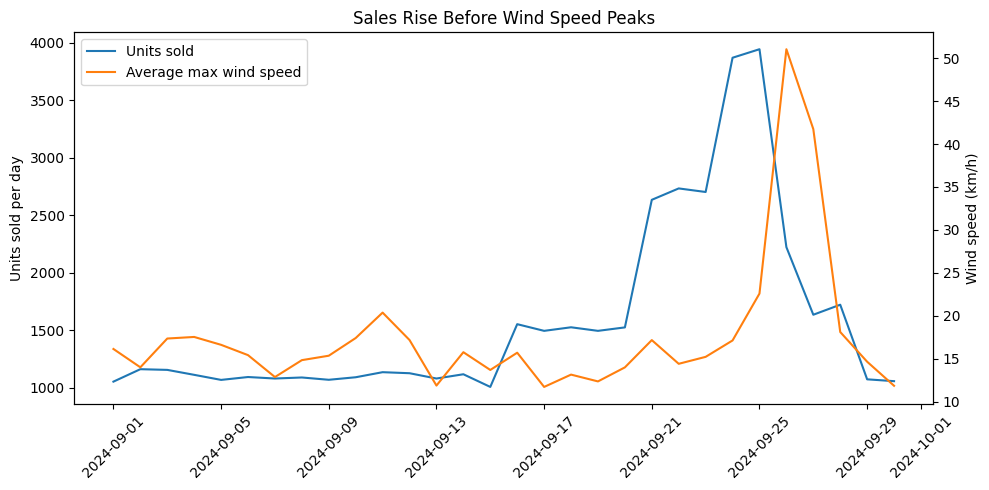

In [8]:
# chart
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(daily.index, daily['units'], color='tab:blue', label='Units sold')
ax1.set_ylabel('Units sold per day')
ax2 = ax1.twinx()
ax2.plot(daily.index, daily['wind'], color='tab:orange', label='Average max wind speed')
ax2.set_ylabel('Wind speed (km/h)')
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc='upper left')
plt.title('Sales Rise Before Wind Speed Peaks')
ax1.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** Sales and weather are weakly related on the same day (wind 0.24, rain -0.30), but sales have a stronger relationship with wind two days later (0.79). Sales start rising around Sept 21 and peak on Sept 25, and wind peaks on Sept 26. This suggests shoppers may have been stocking up before the storm. The weather data came from the Open-Metro API and the join kept all 360 rows with no missing weather. Caveat: We only have 30 days of data and one storm, so the results could change with more data. Also, correlation does not prove the storm caused the increase in sales.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** I found that demand increased across all 12 Walmart stores before the hurricane, but some locations had larger increases than others. Miami had the highest increase at 172.52%, while Orlando had the lowest at 123.70%. I also found that demand increased across all six Florida regions. I've completed the comparisons and charts and am reviewing my results before the presentation.

**Owner: Norah Munoz**

**Q5 (signal or artifact):** It is a signal as well as an artifact because while there is not an +250% increse in entertainment sales during the surge period, there was an increase of around +220%. This increase is not fully transparent because the walmart transactions has rows that did not have timestamps and negative units. There were several record of entertainment supplies in the walmart with missing timestamp in the transaction table and they could not be matched to a specific date.

**Owner: Safaa Mahbub**

### Self-check

In [11]:
progress = {
    'q1_multiple': 5.1,            # TODO: a number
    'q1_baseline_window': 'Sept 1-14, 2024',   # TODO: stated explicitly
    'q2_canonical_products': None,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': None,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.1
PASS - q1_baseline_window = Sept 1-14, 2024
FAIL - q2_canonical_products = None
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
FAIL - charts_with_message_titles = None
FAIL - notebook_runs_clean = False
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a) The surprising part was that sales peaked before the storm. Sales peaked on Sept 25, while wind peaked on Sept 26. We checked the timezone and join to make sure the dates lined up and no weather data was missing. The chart showed the same pattern, with the strongest correlation at 2 days.

b)We are least confident in the 0.79 correlation between sales and wind 2 days later because it only uses 30 days of data and one storm. A few unusual days could change it, and it does not prove the storm caused the increase in sales.